In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import seaborn as sns
from cmcrameri import cm

### Mass balance plots

#### Pilup turnover

In [7]:
time = list(np.linspace(0,440,2201))

data = pd.read_csv('csvForJulius/pileup_turnover.csv', index_col=None, header=None)
data = data.transpose()
data.insert(0, 'Time (min)', time)
data.rename(columns={0: 0, 1:0.001}, inplace=True)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na opti

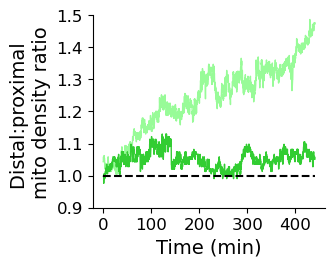

In [8]:
fig, ax = plt.subplots(figsize=(3, 2.5))

sns.lineplot(data=data, x='Time (min)', y=0, color='palegreen', linewidth=1)
sns.lineplot(data=data, x='Time (min)', y=0.001, color='limegreen', linewidth=1)

plt.ylim(0.9, 1.5)
plt.hlines(1, 0, 440, colors='black', linestyles='dashed')
plt.ylabel('Distal:proximal \nmito density ratio', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('Time (min)', fontsize=14)
plt.xticks(fontsize=12)
ax.xaxis.set_major_locator(plt.MultipleLocator(100))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/pileup_turnover.png', dpi=300, bbox_inches='tight')

#### Different on rates

In [9]:
k_on_range = {0:0.00025, 1:0.0005, 2:0.0015, 3:0.004, 4:0.008, 5:0.016}

data = pd.read_csv('csvForJulius/pileup_onrate.csv', index_col=None, header=None)
data = data.transpose()
data.insert(0, 'Time (min)', time)
data.rename(columns=k_on_range, inplace=True)
data = data.melt(id_vars='Time (min)')

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

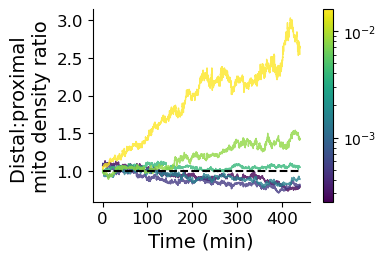

In [10]:
cmap = 'viridis'

fig, ax = plt.subplots(figsize=(3.5,2.5))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=LogNorm(vmin=0.00025, vmax=0.016))

ax = sns.lineplot(data=data, x='Time (min)', y='value', hue='variable', hue_norm=LogNorm(), palette=cmap, linewidth=1, alpha=0.8, legend=False)
plt.hlines(1, 0, 440, colors='black', linestyles='dashed')

plt.ylabel('Distal:proximal \nmito density ratio', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel('Time (min)', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/pileup_onrate.png', dpi=300, bbox_inches='tight')

### Threshold selection plots

Just change the threshold variable to one of the three choices to create the respective plot

In [462]:
threshold = 'fit' #can be either 0fit, high or low


if threshold == 'low':
    file_ext = 'low'
elif threshold == 'high':
    file_ext = 'high'
elif threshold == 'fit':
    file_ext = 'fit'
else:
    print('Invalid threshold')

time_thresh = list(np.linspace(0,90,451))
time_thresh_exp = list(np.linspace(0,90,31))

thresh_N = pd.read_csv('csv_022824/thresh_scatterN' + file_ext + '_round3.csv', index_col=None, header=None)
thresh_N = thresh_N.transpose()
thresh_N.insert(0, 'Time (min)', time_thresh)
thresh_N = thresh_N.melt(id_vars='Time (min)')
thresh_N['Type'] = 'perinuclear'

thresh_P = pd.read_csv('csv_022824/thresh_scatterP' + file_ext + '_round3.csv', index_col=None, header=None)
thresh_P = thresh_P.transpose()
thresh_P.insert(0, 'Time (min)', time_thresh)
thresh_P = thresh_P.melt(id_vars='Time (min)')
thresh_P['Type'] = 'peripheral'

thresh = pd.concat([thresh_N, thresh_P])

thresh_exp = pd.read_csv('csvForJulius/thresh_exp.csv', index_col=None, header=None)
thresh_exp = thresh_exp.transpose()
thresh_exp.insert(0, 'Time (min)', time_thresh_exp)
thresh_exp.rename(columns={0: 'perinuclear', 1:'peripheral'}, inplace=True)


c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is depr

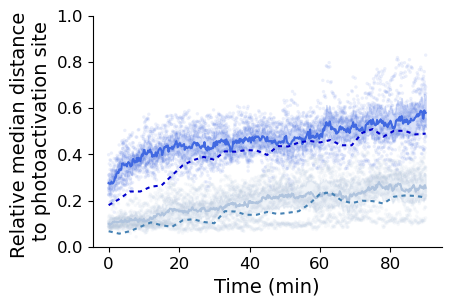

In [464]:
palette = ('royalblue', 'lightsteelblue')

fig, ax = plt.subplots(figsize=(4.5,3))

sns.lineplot(data=thresh, x='Time (min)', y='value', hue='Type', palette=palette, linewidth=1.5, legend=False)
sns.scatterplot(data=thresh, x='Time (min)', y='value', hue='Type', palette=palette, s=6, alpha=0.1, legend=False)

#experimental values
sns.lineplot(data=thresh_exp, x='Time (min)', y='perinuclear', color='mediumblue', linewidth=1.5, dashes=[2,2])
sns.lineplot(data=thresh_exp, x='Time (min)', y='peripheral', color='steelblue', linewidth=1.5, dashes=[2,2])

plt.ylim(0, 1.0)
plt.ylabel('Relative median distance \nto photoactivation site', fontsize=14)
plt.xlabel('Time (min)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.legend(title='')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/thresh_scatter' + file_ext + '.png', dpi=300, bbox_inches='tight')

### C1 C2 plot

In [523]:
size = 'large' #can be either 'large' or 'small

if size ==  'small':
    rhoC1 = np.loadtxt('csv_022824/rhoC1_smallcell.csv', delimiter=',')
    rhoC2 = np.loadtxt('csv_022824/rhoC2_smallcell.csv', delimiter=',')
    save_name = 'rhoC1C2_smallCell.png'
elif size ==  'large':
    rhoC1 = np.loadtxt('csvForJulius/rhoC1.csv', delimiter=',')
    rhoC2 = np.loadtxt('csvForJulius/rhoC2.csv', delimiter=',')
    save_name = 'rhoC1C2_largeCell.png'
else:
    print('Invalid size')

WT_point = [6.96, 0.69, 4.04, 0.31]
TRAK2_kd_point = [2.7, 0.51, 1.6, 0.23]

In [524]:
rhoC1

array([[ 1.24600791,  1.2139727 ,  1.18523303,  1.23040664,  1.22654163],
       [ 2.31861585,  2.26200518,  2.44040378,  2.33374846,  2.23978372],
       [ 4.43974304,  4.36371635,  4.61611635,  4.40747528,  4.57356226],
       [ 9.24532598,  9.06901682,  9.33220971,  9.19091367,  9.43420228],
       [21.55502517, 19.64140754, 20.42171416, 19.82220986, 18.29381553]])

In [525]:
rhoC2

array([[0.11348688, 0.21530852, 0.42482855, 0.81365379, 2.08505759],
       [0.10910561, 0.23222862, 0.44295178, 0.95459859, 2.09153359],
       [0.10555493, 0.20149705, 0.41555628, 0.86273725, 2.26694753],
       [0.10919385, 0.19446084, 0.4460446 , 0.93659816, 2.2012978 ],
       [0.10552943, 0.21005551, 0.43580095, 0.93855728, 1.93598341]])

In [526]:
coords = np.stack((rhoC1, rhoC2), axis=2)

In [527]:
ku1_range = np.logspace(1.25, 1.75, 5)
cmap_C1_C2 = plt.cm.viridis(np.linspace(0, 1, coords.shape[0]))

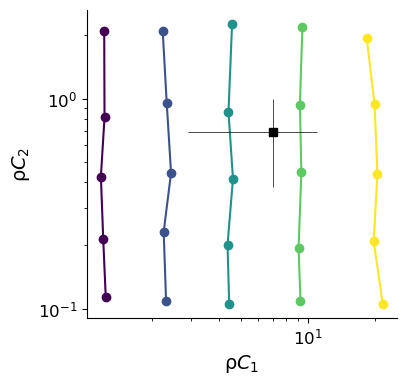

In [529]:
fig, ax = plt.subplots(figsize=(4,4))

for i in range(coords.shape[0]):
    plt.plot(coords[i,:,0], coords[i,:,1], color=cmap_C1_C2[i])
    plt.scatter(coords[i,:,0], coords[i,:,1], color=cmap_C1_C2[i])
plt.errorbar(WT_point[0], WT_point[1], xerr=WT_point[2], yerr=WT_point[3], fmt='s', color='black', lw=0.5)
#plt.errorbar(TRAK2_kd_point[0], TRAK2_kd_point[1], xerr=TRAK2_kd_point[2], yerr=TRAK2_kd_point[3], fmt='^', color='black', lw=0.5)

plt.xlabel(chr(961)+r'$C_{1}$', fontsize=14)
plt.ylabel(chr(961)+r'$C_{2}$', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.xscale('log')
plt.yscale('log')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/'+save_name, dpi=300, bbox_inches='tight')

### Near-far ratio plots

In [476]:
time_nearfar_exp = list(np.linspace(0,90,31))
time_nearfar_sim = list(np.linspace(0,90,451))

data_nearfar_exp = pd.read_csv('csvForJulius/nearfar_exp_wt.csv', index_col=None, header=None)
data_nearfar_exp = data_nearfar_exp.transpose()
data_nearfar_exp.insert(0, 'Time (min)', time_nearfar_exp)
data_nearfar_exp.rename(columns={0: 'Perinuclear', 1:'Peripheral'}, inplace=True)

#For trak2ko use this filename = nearfar_sim_trak2ko.csv
data_nearfar_sim = pd.read_csv('csv_022824/nearfar_sim_wt_round3.csv', index_col=None, header=None)
data_nearfar_sim = data_nearfar_sim.transpose()
data_nearfar_sim.insert(0, 'Time (min)', time_nearfar_sim)
data_nearfar_sim.rename(columns={0: 'Perinuclear', 1:'Peripheral'}, inplace=True)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na opti

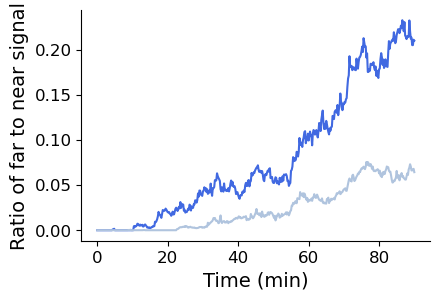

In [480]:
fig, ax = plt.subplots(figsize=(4.5,3))

#sns.lineplot(data=data_nearfar_exp, x='Time (min)', y='Perinuclear', color='royalblue', linestyle='dashed', linewidth=1.5)
#sns.lineplot(data=data_nearfar_exp, x='Time (min)', y='Peripheral', color='lightsteelblue', linestyle='dashed', linewidth=1.5)
sns.lineplot(data=data_nearfar_sim, x='Time (min)', y='Perinuclear', color='royalblue', linewidth=1.5)
sns.lineplot(data=data_nearfar_sim, x='Time (min)', y='Peripheral', color='lightsteelblue', linewidth=1.5)

#plt.ylim(0, 0.7)
plt.ylabel('Ratio of far to near signal', fontsize=14)
plt.xlabel('Time (min)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()
#plt.savefig('plots/nearfar_sim_wt.png', dpi=300, bbox_inches='tight')

### Kymograph plotting

In [481]:
cmap = cm.roma_r

df_N = pd.read_csv('csv_022824/kymoN_sim_wt_round3.csv', index_col=None, header=None)
df_P = pd.read_csv('csv_022824/kymoP_sim_wt_round3.csv', index_col=None, header=None)

#reverse the dataframe to matcht the orientation of the experiment
df_N = df_N.iloc[::15,::-1]
df_P = df_P.iloc[::15,::-1]

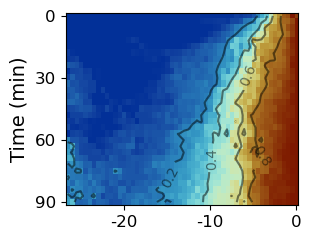

In [482]:
fig, ax = plt.subplots(figsize=(3, 2.5))
plt.imshow(df_N, cmap=cmap, aspect='auto')
contours = plt.contour(df_N, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=12)
plt.xticks([13, 33, 53], [-20, -10, 0], fontsize=12)

plt.show()

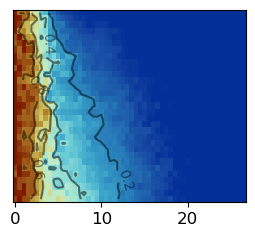

In [483]:
fig, ax = plt.subplots(figsize=(3, 2.5))
plt.imshow(df_P, cmap=cmap, aspect='auto')
contours = plt.contour(df_P, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.tick_params(left=False, labelleft=False)
plt.yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=12)
plt.xticks([0, 20, 40], [0, 10, 20], fontsize=12)

plt.show()

In [484]:
df_N_exp = pd.read_csv('csvForJulius/kymoN_exp_wt.csv', index_col=None, header=None)
df_P_exp = pd.read_csv('csvForJulius/kymoP_exp_wt.csv', index_col=None, header=None)

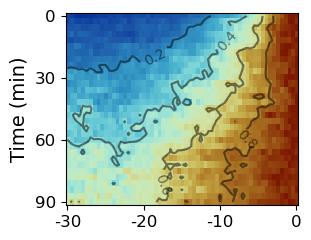

In [485]:
fig, ax = plt.subplots(figsize=(3, 2.5))
plt.imshow(df_N_exp, cmap=cmap, aspect='auto')
contours = plt.contour(df_N_exp, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.ylabel('Time (min)', fontsize=14)
plt.yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=12)
plt.xticks([0, 20, 40, 60], [-30, -20, -10, 0], fontsize=12)

plt.show()

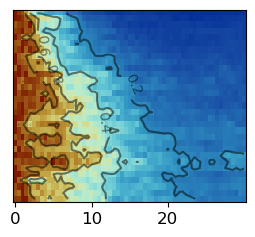

In [486]:
fig, ax = plt.subplots(figsize=(3, 2.5))
plt.imshow(df_P_exp, cmap=cmap, aspect='auto')
contours = plt.contour(df_P_exp, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
plt.clabel(contours, inline=True, fontsize=10)

#Axes tick labelling
plt.tick_params(left=False, labelleft=False)
plt.yticks([0,10,20,30], [0,30,60,90], rotation=0, fontsize=12)
plt.xticks([0, 20, 40], [0, 10, 20], fontsize=12)

plt.show()

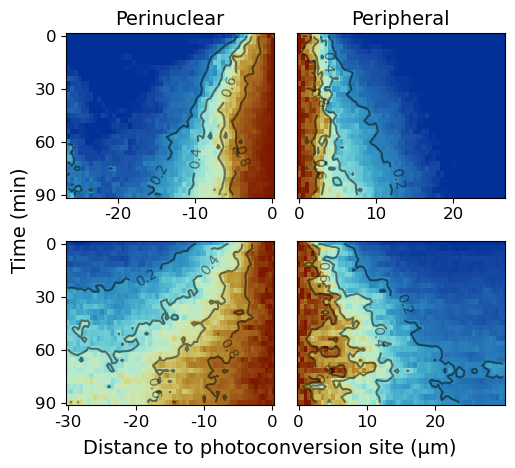

In [489]:
fig, axs = plt.subplots(2, 2, figsize=(5, 4.5))

# Plot df_N
axs[0, 0].imshow(df_N, cmap=cmap, aspect='auto')
contours = axs[0, 0].contour(df_N, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
axs[0, 0].clabel(contours, inline=True, fontsize=10)
axs[0, 0].set_title('Perinuclear', fontsize=14)
axs[0, 0].set_yticks([0, 10, 20, 30])
axs[0, 0].set_yticklabels([0, 30, 60, 90], rotation=0, fontsize=12)
axs[0, 0].set_xticks([13, 33, 53])
axs[0, 0].set_xticklabels([-20, -10, 0], fontsize=12)

# Plot df_P
axs[0, 1].imshow(df_P, cmap=cmap, aspect='auto')
contours = axs[0, 1].contour(df_P, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
axs[0, 1].clabel(contours, inline=True, fontsize=10)
axs[0, 1].tick_params(left=False, labelleft=False)
axs[0, 1].set_title('Peripheral', fontsize=14)
axs[0, 1].set_yticks([0, 10, 20, 30])
axs[0, 1].set_yticklabels([0, 30, 60, 90], rotation=0, fontsize=12)
axs[0, 1].set_xticks([0, 20, 40])
axs[0, 1].set_xticklabels([0, 10, 20], fontsize=12)

# Plot df_N_exp
axs[1, 0].imshow(df_N_exp, cmap=cmap, aspect='auto')
contours = axs[1, 0].contour(df_N_exp, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
axs[1, 0].clabel(contours, inline=True, fontsize=10)
axs[1, 0].set_yticks([0, 10, 20, 30])
axs[1, 0].set_yticklabels([0, 30, 60, 90], rotation=0, fontsize=12)
axs[1, 0].set_xticks([0, 20, 40, 60])
axs[1, 0].set_xticklabels([-30, -20, -10, 0], fontsize=12)

# Plot df_P_exp
axs[1, 1].imshow(df_P_exp, cmap=cmap, aspect='auto')
contours = axs[1, 1].contour(df_P_exp, levels=[0.2, 0.4, 0.6, 0.8, 1.0], colors='black', alpha=0.5)
axs[1, 1].clabel(contours, inline=True, fontsize=10)
axs[1, 1].tick_params(left=False, labelleft=False)
axs[1, 1].set_yticks([0, 10, 20, 30])
axs[1, 1].set_yticklabels([0, 30, 60, 90], rotation=0, fontsize=12)
axs[1, 1].set_xticks([0, 20, 40])
axs[1, 1].set_xticklabels([0, 10, 20], fontsize=12)

#set a shared ylabel for both rows
fig.text(-0.02, 0.5, 'Time (min)', va='center', rotation='vertical', fontsize=14)

#set a shared xlabel for both columns
fig.text(0.5, -0.02, 'Distance to photoconversion site (µm)', ha='center', fontsize=14)

plt.tight_layout()
plt.show()
#plt.savefig('plots/kymo_sim_exp_wt.png', dpi=300, bbox_inches='tight')


### Observed runs plots

#### wt (large cell)

In [47]:
keys = np.linspace(0,4,5)
values = np.logspace(-3.5,-2,5)*0.5

k_rem_range = dict(zip(keys, values))
k_on_range = np.logspace(-2.5, -1.5, 5)*0.5

runs_data = pd.read_csv('csvForJulius/observedrunsmean_wt.csv', index_col=None, header=None)
runs_data.insert(0, 'k_on', k_on_range)
runs_data.rename(columns=k_rem_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_on')

runs_std = pd.read_csv('csvForJulius/observedrunsstd_wt.csv', index_col=None, header=None)
runs_std.insert(0, 'k_on', k_on_range)
runs_std.rename(columns=k_rem_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_on')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_on', 'variable'])

In [48]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

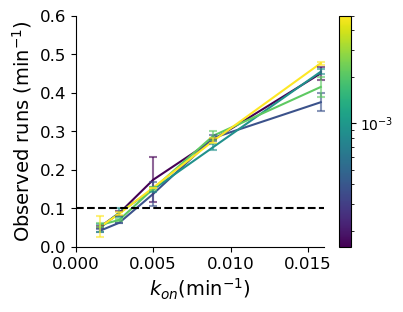

In [50]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_on', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_on'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(0.1, 0, 0.016, colors='black', linestyles='dashed')

plt.xlim(0, 0.016)
plt.ylim(0, 0.6)
plt.ylabel('Observed runs (min' + r'$^{-1})$', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{on}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/observedruns_wt_large.png', dpi=300, bbox_inches='tight')

#### wt (small cell)

In [51]:
keys = np.linspace(0,4,5)
values = np.logspace(-3, -2, 5)*0.5

k_rem_range = dict(zip(keys, values))
k_on_range = np.logspace(-2.7, -1.6, 5)*0.5

runs_data = pd.read_csv('csv_022824/observedrunsmean_wt_round3.csv', index_col=None, header=None)
runs_data.insert(0, 'k_on', k_on_range)
runs_data.rename(columns=k_rem_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_on')

runs_std = pd.read_csv('csv_022824/observedrunsstd_wt_round3.csv', index_col=None, header=None)
runs_std.insert(0, 'k_on', k_on_range)
runs_std.rename(columns=k_rem_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_on')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_on', 'variable'])

In [52]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

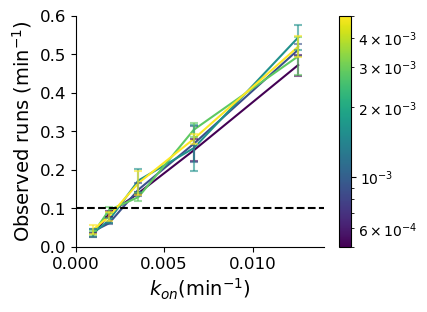

In [54]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_on', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_on'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(0.1, 0, 0.014, colors='black', linestyles='dashed')

plt.xlim(0, 0.014)
plt.ylim(0, 0.6)
plt.ylabel('Observed runs (min' + r'$^{-1})$', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{on}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/observedruns_wt_small.png', dpi=300, bbox_inches='tight')

#### TRAK2 kd

In [14]:
keys = np.linspace(0,4,5)
values = np.logspace(-4,-2.5,5)*0.5

k_rem_range = dict(zip(keys, values))
k_on_range = np.logspace(-3.5, -2, 5)*0.5

runs_data = pd.read_csv('csvForJulius/observedrunsmean_trak2ko.csv', index_col=None, header=None)
runs_data.insert(0, 'k_on', k_on_range)
runs_data.rename(columns=k_rem_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_on')

runs_std = pd.read_csv('csvForJulius/observedrunsstd_trak2ko.csv', index_col=None, header=None)
runs_std.insert(0, 'k_on', k_on_range)
runs_std.rename(columns=k_rem_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_on')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_on', 'variable'])

In [15]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

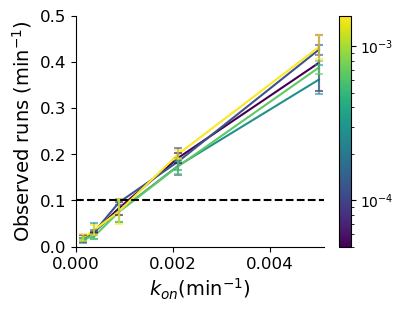

In [16]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_on', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_on'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(0.1, 0, 0.0051, colors='black', linestyles='dashed')

plt.xlim(0, 0.0051)
plt.ylim(0, 0.5)
plt.ylabel('Observed runs (min' + r'$^{-1})$', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{on}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/observedruns_trak2ko.png', dpi=300, bbox_inches='tight')

### Doubling time plots

#### wt (large cell)

In [55]:
keys = np.linspace(0,4,5)
values = np.logspace(-2.5, -1.5, 5)*0.5

k_on_range = dict(zip(keys, values))
k_rem_range = np.logspace(-3.5,-2,5)*0.5


runs_data = pd.read_csv('csvForJulius/doublingmean_wt.csv', index_col=None, header=None)
runs_data = runs_data.transpose()
runs_data.insert(0, 'k_rem', k_rem_range)
runs_data.rename(columns=k_on_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_rem')

runs_std = pd.read_csv('csvForJulius/doublingstd_wt.csv', index_col=None, header=None)
runs_std = runs_std.transpose()
runs_std.insert(0, 'k_rem', k_rem_range)
runs_std.rename(columns=k_on_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_rem')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_rem', 'variable'])

In [56]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

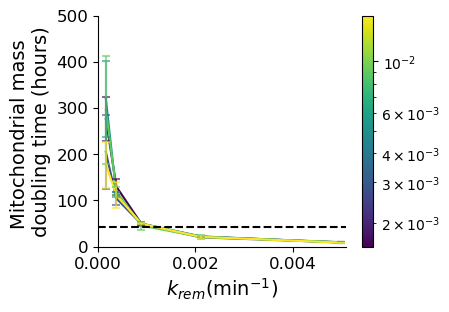

In [58]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_rem', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_rem'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(42, 0, 0.0051, colors='black', linestyles='dashed')

plt.xlim(0, 0.0051)
plt.ylim(0, 500)
plt.ylabel('Mitochondrial mass \ndoubling time (hours)', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{rem}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/doubling_wt_large.png', dpi=300, bbox_inches='tight')

#### wt (small cell)

In [59]:
keys = np.linspace(0,4,5)
values = np.logspace(-2.7, -1.6, 5)*0.5

k_on_range = dict(zip(keys, values))
k_rem_range = np.logspace(-3, -2, 5)*0.5


runs_data = pd.read_csv('csv_022824/doublingmean_wt_round3.csv', index_col=None, header=None)
runs_data = runs_data.transpose()
runs_data.insert(0, 'k_rem', k_rem_range)
runs_data.rename(columns=k_on_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_rem')

runs_std = pd.read_csv('csv_022824/doublingstd_wt_round3.csv', index_col=None, header=None)
runs_std = runs_std.transpose()
runs_std.insert(0, 'k_rem', k_rem_range)
runs_std.rename(columns=k_on_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_rem')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_rem', 'variable'])

In [60]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

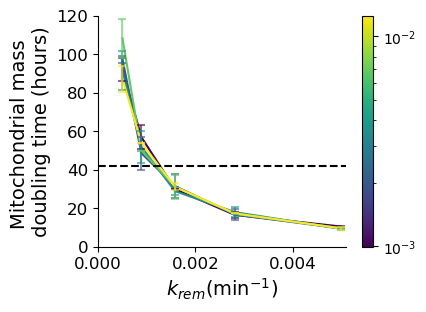

In [62]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_rem', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_rem'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(42, 0, 0.0051, colors='black', linestyles='dashed')

plt.xlim(0, 0.0051)
plt.ylim(0, 120)
plt.ylabel('Mitochondrial mass \ndoubling time (hours)', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{rem}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/doubling_wt_small.png', dpi=300, bbox_inches='tight')

#### TRAK2 kd

In [26]:
keys = np.linspace(0,4,5)
values = np.logspace(-3.5, -2, 5)*0.5

k_on_range = dict(zip(keys, values))
k_rem_range = np.logspace(-4,-2.5,5)*0.5


runs_data = pd.read_csv('csvForJulius/doublingmean_trak2ko.csv', index_col=None, header=None)
runs_data = runs_data.transpose()
runs_data.insert(0, 'k_rem', k_rem_range)
runs_data.rename(columns=k_on_range, inplace=True)
runs_data = runs_data.melt(id_vars='k_rem')

runs_std = pd.read_csv('csvForJulius/doublingstd_trak2ko.csv', index_col=None, header=None)
runs_std = runs_std.transpose()
runs_std.insert(0, 'k_rem', k_rem_range)
runs_std.rename(columns=k_on_range, inplace=True)
runs_std = runs_std.melt(id_vars='k_rem')
runs_std.rename(columns={'value':'std'}, inplace=True)

runs_data = pd.merge(runs_data, runs_std, on=['k_rem', 'variable'])

In [27]:
cmap_runs = plt.cm.viridis(np.linspace(0, 1, len(values)))
cmap_runs = np.repeat(cmap_runs, len(values), axis=0)

c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
c:\Users\winter\AppData\Local\mambaforge\envs\mitoflow\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is depr

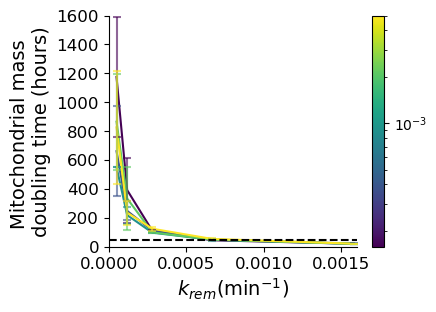

In [28]:
fig, ax = plt.subplots(figsize=(4, 3))
sm = plt.cm.ScalarMappable(cmap='viridis', norm=LogNorm(vmin=values[0], vmax=values[-1]))

sns.lineplot(data=runs_data, x='k_rem', y='value', hue='variable', hue_norm=LogNorm(), palette='viridis', linewidth=1.5, legend=False, ax=ax)
#plot error bar for each point using the std column for error
for i in range(len(runs_data)):
    plt.errorbar(runs_data['k_rem'][i], runs_data['value'][i], yerr=runs_data['std'][i], color=cmap_runs[i], capsize=3, capthick=1.5, elinewidth=1.5, alpha=0.6)

plt.hlines(42, 0, 0.0016, colors='black', linestyles='dashed')

plt.xlim(0, 0.0016)
plt.ylim(0, 1600)
plt.ylabel('Mitochondrial mass \ndoubling time (hours)', fontsize=14)
plt.yticks(fontsize=12)
plt.xlabel(r'$k_{rem}$' + '(min' + r'$^{-1})$', fontsize=14)
plt.xticks(fontsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.figure.colorbar(sm, ax=ax)

plt.show()
#plt.savefig('plots/doubling_trak2ko.png', dpi=300, bbox_inches='tight')